# 🔗 Live Deployment Link: **https://YOUR-APP-NAME.streamlit.app/**  *(replace after deploying)*

# Property Price Prediction System – 10-Fold Cross Validation (Full Dataset)

## Setup: Running This Notebook on Google Colab

1. Go to **https://colab.research.google.com** and sign in with a Google account.
2. Click **File → Upload notebook** and choose this `.ipynb` file.
3. Click **Runtime → Run all**.
4. When **Step 2.1** runs, a **"Choose Files"** button appears. Select **`Property_with_Feature_Engineering.csv`**. The notebook continues automatically after the upload (the file is about 65 MB, so the upload may take a minute).

> **Note:** Colab deletes uploaded files when the runtime is reset. If you get a *"file not found"* error, run Step 2.1 again and re-upload the CSV.

---

## Introduction

##### **Definition** A regression ML task that predicts the **price (in Pakistani Rupees)** of a property listed on Zameen.com from its type, city, location, size, number of bedrooms and bathrooms, and whether it is for sale or for rent.
##### **Application** Property portals (instant price estimates), buyers and sellers checking whether a listing is fairly priced, rental valuation, real-estate agencies and mortgage / loan collateral assessment.

### Aim of This Notebook

The Car Price notebook compared Linear Regression, KNN, Decision Tree, Random Forest and Gradient Boosting. This notebook answers the same question on a **different, larger real-world problem** and with **5 different algorithms**:

> **Which of 5 regression algorithms (Ridge Regression, Extra Trees, Histogram Gradient Boosting, AdaBoost and an MLP Neural Network) predicts property prices best, and how sure can we be about that answer?**

We use **10-Fold Cross Validation** on the **full dataset** and compare the algorithms using **Root Mean Squared Error (RMSE)**.

### What is K-Fold Cross Validation?

1. Shuffle the data and split it into **K equal parts (folds)**.
2. Train the model on **K−1 folds** and test it on the **remaining fold**.
3. Repeat **K times**, so that **every fold is used as the test set exactly once**.
4. Report the **average** score over the K rounds (and the standard deviation, to show how much it varies).

With **K = 10**, every property is used for testing exactly once and for training 9 times.

### Evaluation Measure: Root Mean Squared Error (RMSE)

$$RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}$$

- $y_i$ = actual price, $\hat{y}_i$ = predicted price, $n$ = number of test properties
- RMSE is in the **same unit as the output (Pakistani Rupees)**. Because property prices are very large, we show RMSE in **millions of rupees (Rs M)**.
- **Lower RMSE = better model.** Because errors are squared, RMSE penalises **large mistakes** heavily.

## Input and Output

### Input (Features / Attributes)

| Feature | Description | Type |
|---|---|---|
| **property_type** | House, Flat, Upper Portion, Lower Portion, Room, Farm House, Penthouse | Categorical |
| **city** | Karachi, Lahore, Islamabad, Rawalpindi, Faisalabad | Categorical |
| **location** | Neighbourhood / society (e.g. DHA Defence, Gulberg, Bahria Town) | Categorical |
| **purpose** | For Sale or For Rent | Categorical |
| **latitude, longitude** | GPS position of the property | Numerical |
| **area_sqft** | Size of the property in square feet (converted from Marla / Kanal) | Numerical |
| **bedrooms, baths** | Number of bedrooms and bathrooms | Numerical |

### Output (Prediction)

| Output Attribute | Description | Data Type |
|---|---|---|
| **price** | Listed price of the property in Pakistani Rupees (sale price, or monthly rent for rentals) | Numerical |

## Developer & System Information

| **Attribute** | **Details** |
|---|---|
| **Developer Name** | *Your Name* (Reg. No. *your reg no*) |
| **Course** | Machine Learning Fundamentals (AIC354), COMSATS University Islamabad, Lahore Campus |
| **Program Name** | `property_price_kfold_full_dataset_10fold` |
| **IDE** | Google Colab |
| **Programming Language** | Python 3 |
| **Libraries** | NumPy, Pandas, scikit-learn, Matplotlib, tqdm, Pickle (built-in). Exact versions are printed in Step 1. |
| **Dataset** | `Property_with_Feature_Engineering.csv` (Zameen.com listings, 191,393 rows before cleaning) |

### Table of Contents
- **Step 1:** Import Libraries
- **Step 2:** Load Sample Data (2.1 Upload, 2.2 Read)
- **Step 3:** Understand and Pre-process Sample Data
- **Step 4:** Feature Extraction
- **Step 5:** Build the Pre-processing Pipeline
- **Step 6:** Define the 5 Regression Algorithms
- **Step 7:** Set Up 10-Fold Cross Validation
- **Step 8:** Run 10-Fold Cross Validation for All 5 Algorithms
- **Step 9:** Compare the Algorithms
- **Step 10:** Train the Final Model
- **Step 11:** Execute the Application Phase
- **Step 12:** Execute the Feedback Phase
- **Conclusion**

# Code – Property Price Prediction System
## Step 1: Import Libraries

In [1]:
# --- Core Python Libraries ---
import os
import pickle
import time
import warnings

import numpy as np
import pandas as pd

# --- Machine Learning (scikit-learn) ---
import sklearn
from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# --- The 5 Regression Algorithms (none of them are used in the Car Price notebooks) ---
from sklearn.linear_model import Ridge
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor, AdaBoostRegressor
from sklearn.neural_network import MLPRegressor

# --- Visualization ---
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

# --- Progress bar (shows elapsed and remaining time) ---
from tqdm import tqdm

warnings.filterwarnings("ignore")      # hide harmless convergence / deprecation warnings
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

print("Library versions used in this run:")
print(f"  NumPy        : {np.__version__}")
print(f"  Pandas       : {pd.__version__}")
print(f"  scikit-learn : {sklearn.__version__}")
print(f"  Matplotlib   : {matplotlib.__version__}")

Library versions used in this run:
  NumPy        : 2.4.4
  Pandas       : 3.0.2
  scikit-learn : 1.8.0
  Matplotlib   : 3.10.8


# Step 2: Load Sample Data
## Step 2.1: Upload the Dataset (Google Colab)

When this cell runs in Google Colab, a **"Choose Files"** button appears. Select **`Property_with_Feature_Engineering.csv`**. If the file is already present, the upload is skipped.

In [2]:
DATA_FILE = "Property_with_Feature_Engineering.csv"

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and not os.path.exists(DATA_FILE):
    print(f"Please click 'Choose Files' and select '{DATA_FILE}' ...")
    uploaded = files.upload()
    uploaded_name = list(uploaded.keys())[0]
    if uploaded_name != DATA_FILE:
        os.rename(uploaded_name, DATA_FILE)

if os.path.exists(DATA_FILE):
    print(f"'{DATA_FILE}' is ready to use.")
else:
    raise FileNotFoundError(f"'{DATA_FILE}' not found. Please run this cell again and upload it.")

'Property_with_Feature_Engineering.csv' is ready to use.


## Step 2.2: Read the Dataset

This notebook uses the **full** dataset (no sampling).

In [3]:
properties = pd.read_csv(DATA_FILE)
print(f"Loaded dataset: {properties.shape[0]:,} listings, {properties.shape[1]} attributes")
properties.head()

Loaded dataset: 191,393 listings, 24 attributes


,property_id,location_id,page_url,property_type,price,price_bin,location,city,province_name,locality,...,area_marla,area_sqft,purpose,bedrooms,date_added,year,month,day,agency,agent
0,347795,8,https://www.zameen.com/Property/lahore_model_t...,House,220000000,Very High,Model Town,Lahore,Punjab,"Model Town, Lahore, Punjab",...,120.00,"32,670.12",For Sale,0,07-17-2019,2019,7,17,Real Biz International,Usama Khan
1,482892,48,https://www.zameen.com/Property/lahore_multan_...,House,40000000,Very High,Multan Road,Lahore,Punjab,"Multan Road, Lahore, Punjab",...,20.00,"5,445.02",For Sale,5,10-06-2018,2018,10,6,Khan Estate,mohsinkhan and B
2,555962,75,https://www.zameen.com/Property/eden_eden_aven...,House,9500000,Low,Eden,Lahore,Punjab,"Eden, Lahore, Punjab",...,9.00,"2,450.26",For Sale,3,07-03-2019,2019,7,3,Shahum Estate 2,"Babar Hameed, Raja Omar"
3,562843,3821,https://www.zameen.com/Property/gulberg_2_gulb...,House,125000000,Very High,Gulberg,Lahore,Punjab,"Gulberg, Lahore, Punjab",...,20.00,"5,445.02",For Sale,8,04-04-2019,2019,4,4,NaN,NaN
4,686990,3522,https://www.zameen.com/Property/allama_iqbal_t...,House,21000000,High,Allama Iqbal Town,Lahore,Punjab,"Allama Iqbal Town, Lahore, Punjab",...,11.00,"2,994.76",For Sale,6,04-04-2019,2019,4,4,NaN,NaN


# Step 3: Understand and Pre-process Sample Data
## Step 3.1: Understand Sample Data

In [4]:
print("\nAttributes in Sample Data:")
print("==========================\n")
print(list(properties.columns))

print("\nNumber of Instances in Sample Data:")
print("===================================\n")
print(len(properties))

print("\nMissing Values in Each Attribute:")
print("=================================\n")
missing = properties.isnull().sum()
print(missing[missing > 0])
print("\n(agency / agent are missing for ~25% of listings; we do not use them as features.)")

print("\nListings by city:")
print(properties["city"].value_counts().to_string())
print("\nListings by purpose:")
print(properties["purpose"].value_counts().to_string())


Attributes in Sample Data:

['property_id', 'location_id', 'page_url', 'property_type', 'price', 'price_bin', 'location', 'city', 'province_name', 'locality', 'latitude', 'longitude', 'baths', 'area', 'area_marla', 'area_sqft', 'purpose', 'bedrooms', 'date_added', 'year', 'month', 'day', 'agency', 'agent']

Number of Instances in Sample Data:

191393

Missing Values in Each Attribute:

agency    47379
agent     47380
dtype: int64

(agency / agent are missing for ~25% of listings; we do not use them as features.)

Listings by city:
city
Karachi       60484
Lahore        58736
Islamabad     40195
Rawalpindi    22898
Faisalabad     9080

Listings by purpose:
purpose
For Sale    127018
For Rent     64375


### Understanding the Output (price)

Property prices are **extremely skewed**: a rental can be Rs 30,000 per month, a house for sale can cost Rs 20,000,000, and a few mansions and plots are listed for over Rs 1,000,000,000. Also, the data mixes **two kinds of price**: *sale prices* (millions) and *monthly rents* (tens of thousands). The `purpose` feature tells the model which one it is predicting.

In [5]:
price_summary = properties.groupby("purpose")["price"].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99])
price_summary.style.format("{:,.0f}")

,count,mean,std,min,25%,50%,75%,95%,99%,max
purpose,,,,,,,,,,
For Rent,"64,375","91,136","178,537",0,"30,000","45,000","85,000","300,000","700,000","17,000,000"
For Sale,"127,018","24,735,772","39,426,390",0,"7,500,000","13,500,000","26,000,000","80,000,000","180,000,000","2,000,000,000"


> **Why this matters for RMSE:** RMSE squares each error, so **a few badly predicted multi-hundred-million properties can raise the RMSE more than thousands of well-predicted ordinary homes**, and almost all of the RMSE comes from *sale* listings (rent errors are tiny in comparison). Keep this in mind when reading the results.

## Step 3.2: Pre-process Sample Data

In [6]:
"""
Pre-processing steps (all done BEFORE cross validation):
--------------------------------------------------------
1. Remove duplicate listings. The same property is often posted several times
   (different listing ID, same details). Duplicates are harmful in cross validation:
   the same property could land in BOTH the training folds and the test fold, so the
   model would be tested on a property it has already seen and the RMSE would look
   better than it really is.
2. Remove rows with impossible values (wrong GPS position, zero / huge area,
   absurd number of rooms, or prices that are clearly typing errors).
3. Missing values: the features we use have none, but the pipeline in Step 5 still
   contains an imputer so that it also works for new data.
"""

FEATURE_COLUMNS = ["latitude", "longitude", "baths", "bedrooms", "area_sqft",
                   "property_type", "city", "purpose", "location"]

data = properties.copy()
log = [("Original listings", len(data))]

# 1. duplicates (same property details AND same price)
data = data.drop_duplicates(subset=FEATURE_COLUMNS + ["price"])
log.append(("After removing duplicate listings", len(data)))

# 2. impossible values
data = data[data["latitude"].between(23, 37) & data["longitude"].between(60, 78)]
log.append(("After removing GPS positions outside Pakistan", len(data)))

data = data[data["area_sqft"].between(1, 200_000)]
log.append(("After removing area = 0 or > 200,000 sq ft", len(data)))

data = data[(data["baths"] <= 15) & (data["bedrooms"] <= 15)]
log.append(("After removing > 15 bedrooms / bathrooms", len(data)))

plausible = ((data["purpose"] == "For Sale") & (data["price"] >= 100_000)) | \
            ((data["purpose"] == "For Rent") & (data["price"] >= 2_000))
data = data[plausible].reset_index(drop=True)
log.append(("After removing implausibly low prices", len(data)))

cleaning_log = pd.DataFrame(log, columns=["Step", "Listings remaining"]).set_index("Step")
cleaning_log.style.format("{:,.0f}")

,Listings remaining
Step,
Original listings,"191,393"
After removing duplicate listings,"129,027"
After removing GPS positions outside Pakistan,"129,017"
"After removing area = 0 or > 200,000 sq ft","128,927"
After removing > 15 bedrooms / bathrooms,"128,911"
After removing implausibly low prices,"128,828"


# Step 4: Feature Extraction

We separate the **input (X)** from the **output (y)**. We deliberately do **not** use `price_bin` (it is made *from* the price, so it would leak the answer), nor IDs, URLs, agency or agent names.

In [7]:
numeric_features = ["latitude", "longitude", "baths", "bedrooms", "area_sqft"]
categorical_features = ["property_type", "city", "purpose", "location"]
target = "price"

X = data[numeric_features + categorical_features]
y = data[target]

print(f"Input features (X): {X.shape[1]} columns -> {list(X.columns)}")
print(f"Output (y)        : {target}")
print(f"Number of listings: {len(X):,}")
X.head()

Input features (X): 9 columns -> ['latitude', 'longitude', 'baths', 'bedrooms', 'area_sqft', 'property_type', 'city', 'purpose', 'location']
Output (y)        : price
Number of listings: 128,828


,latitude,longitude,baths,bedrooms,area_sqft,property_type,city,purpose,location
0,31.48,74.33,0,0,"32,670.12",House,Lahore,For Sale,Model Town
1,31.43,74.18,5,5,"5,445.02",House,Lahore,For Sale,Multan Road
2,31.50,74.42,0,3,"2,450.26",House,Lahore,For Sale,Eden
3,31.52,74.36,7,8,"5,445.02",House,Lahore,For Sale,Gulberg
4,31.51,74.29,5,6,"2,994.76",House,Lahore,For Sale,Allama Iqbal Town


# Step 5: Build the Pre-processing Pipeline

| Feature type | Step | Why |
|---|---|---|
| Numeric | **Fill missing values** with the median | Algorithms cannot handle empty values |
| Numeric | **Standard scaling** (mean 0, std 1) | So that `area_sqft` (thousands) does not dominate `bedrooms` (single digits) |
| Categorical | **One-hot encoding** | Turns text categories into 0/1 columns without inventing a fake order |

**Rare locations:** the data has ~1,500 different locations, many with only a handful of listings. `min_frequency=200` groups every location with fewer than 200 listings into one "other" column, which keeps the number of columns manageable (latitude and longitude still describe where such a property is).

**Why inside the pipeline?** The scaler and imputer must be fitted on the **training folds only** in each round, otherwise they "see" the test fold (data leakage). Placing them inside the pipeline guarantees this.

In [8]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                             min_frequency=200, sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

print("Pre-processing pipeline created:")
preprocessor

Pre-processing pipeline created:


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

# Step 6: Define the 5 Regression Algorithms

| # | Algorithm | How it predicts a price |
|---|---|---|
| 1 | **Ridge Regression** | A linear model (weighted sum of features) with a penalty on large weights, so it stays stable when many one-hot columns are correlated |
| 2 | **Extra Trees** | Builds many decision trees whose split points are chosen **randomly**, then averages them. Faster and often smoother than a Random Forest |
| 3 | **Histogram Gradient Boosting** | Builds trees one after another, each correcting the errors of the previous ones. Bins features into histograms so it is very fast on large data |
| 4 | **AdaBoost** | Builds many small trees one after another and gives more weight to the examples that earlier trees got wrong |
| 5 | **MLP Neural Network** | A small neural network (two hidden layers of 64 and 32 neurons) that learns non-linear combinations of the features |

> **Note on the MLP:** neural networks train badly when the output is in the hundreds of millions. We wrap it in `TransformedTargetRegressor`, which scales the price for training and converts the prediction **back to rupees**, so its RMSE is still measured in rupees like the others.
>
> **Note on Extra Trees:** with `n_estimators=50` and `min_samples_leaf=3` it trains in a reasonable time on 129k properties. All algorithms otherwise use default settings (no hyper-parameter tuning), and `random_state=42` makes the results reproducible.

In [9]:
algorithms = {
    "Ridge Regression": Ridge(),
    "Extra Trees": ExtraTreesRegressor(n_estimators=50, min_samples_leaf=3, random_state=42, n_jobs=-1),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=50, random_state=42),
    "MLP Neural Network": TransformedTargetRegressor(
        regressor=MLPRegressor(hidden_layer_sizes=(64, 32), early_stopping=True,
                               max_iter=100, random_state=42),
        transformer=StandardScaler()),
}

print("Algorithms to compare:")
for number, name in enumerate(algorithms, start=1):
    print(f"  {number}. {name}")

Algorithms to compare:
  1. Ridge Regression
  2. Extra Trees
  3. Hist Gradient Boosting
  4. AdaBoost
  5. MLP Neural Network


# Step 7: Set Up 10-Fold Cross Validation
## Step 7.1: Create the K-Fold Splitter

- `n_splits=10`: split the data into 10 folds
- `shuffle=True`: shuffle first, because the file is not in random order
- `random_state=42`: the **same folds are used for all 5 algorithms**, so every algorithm is tested on exactly the same properties (a fair comparison)

In [10]:
K = 10
kfold = KFold(n_splits=K, shuffle=True, random_state=42)
print(f"{K}-Fold Cross Validation created (shuffle=True, random_state=42)")

10-Fold Cross Validation created (shuffle=True, random_state=42)


## Step 7.2: Inspect the Folds

In [11]:
fold_sizes = []
for fold_number, (train_index, test_index) in enumerate(kfold.split(X), start=1):
    fold_sizes.append({
        "Fold (Round)": fold_number,
        "Training Properties": len(train_index),
        "Testing Properties": len(test_index),
        "Avg Price of Test Set (Rs M)": y.iloc[test_index].mean() / 1e6,
        "Most Expensive Test Property (Rs M)": y.iloc[test_index].max() / 1e6,
    })

pd.DataFrame(fold_sizes).set_index("Fold (Round)")

,Training Properties,Testing Properties,Avg Price of Test Set (Rs M),Most Expensive Test Property (Rs M)
Fold (Round),,,,
1,115945,12883,17.21,"1,200.00"
2,115945,12883,17.13,"1,250.00"
3,115945,12883,17.10,"1,450.00"
4,115945,12883,17.54,"2,000.00"
5,115945,12883,17.09,"1,250.00"
6,115945,12883,16.53,"1,000.00"
7,115945,12883,17.34,"1,350.00"
8,115945,12883,16.64,750.00
9,115946,12882,16.91,850.00


The **most expensive test property** is very different in each fold. A fold that happens to contain a multi-hundred-million listing will usually have a **higher RMSE**, because of the squaring explained in Step 3.1.

# Step 8: Run 10-Fold Cross Validation for All 5 Algorithms

For each algorithm we build a pipeline (**pre-processing → algorithm**). For each of the 10 folds we: (1) make a **fresh copy** of the pipeline (`clone`), (2) **train** it on the training folds, (3) **predict** the test fold, and (4) calculate the **RMSE**.

### Progress Bar (tqdm)

There is one step per algorithm per fold, so the bar has **5 × 10 = 50 steps**. It shows the algorithm and fold being trained, the **elapsed time** and the **estimated remaining time**, for example:

```
Extra Trees, fold 2/10:  24%|██▍       | 12/50 [03:35<11:20, 17.9s/fold]
```

> ⏱ **This step takes several minutes in Colab.** Extra Trees is the slowest algorithm.

In [12]:
fold_rmse = {}        # RMSE on each fold, for each algorithm
training_time = {}    # total time taken for all folds

folds = list(kfold.split(X))     # the same folds for every algorithm
total_steps = len(algorithms) * K

with tqdm(total=total_steps, unit="fold") as progress_bar:
    for name, algorithm in algorithms.items():
        model = Pipeline([
            ("preprocessor", preprocessor),
            ("regressor", algorithm),
        ])

        scores = []
        start = time.time()
        for fold_number, (train_index, test_index) in enumerate(folds, start=1):
            progress_bar.set_description(f"{name}, fold {fold_number}/{K}")

            fold_model = clone(model)                                   # fresh, untrained copy
            fold_model.fit(X.iloc[train_index], y.iloc[train_index])    # train on K-1 folds
            predictions = fold_model.predict(X.iloc[test_index])        # test on 1 fold
            rmse = np.sqrt(mean_squared_error(y.iloc[test_index], predictions))
            scores.append(rmse)

            progress_bar.update(1)

        training_time[name] = time.time() - start
        fold_rmse[name] = np.array(scores)
        tqdm.write(f"{name:<24} -> mean RMSE = Rs {fold_rmse[name].mean()/1e6:>7,.2f} M   ({training_time[name]:.1f} s)")

    progress_bar.set_description("Done")

print(f"\n{K}-fold cross validation completed for all {len(algorithms)} algorithms.")

Ridge Regression         -> mean RMSE = Rs   29.17 M   (6.6 s)


Extra Trees              -> mean RMSE = Rs   15.21 M   (444.0 s)


Hist Gradient Boosting   -> mean RMSE = Rs   15.22 M   (63.4 s)


AdaBoost                 -> mean RMSE = Rs   52.25 M   (111.5 s)


Done: 100%|██████████| 50/50 [12:31<00:00, 15.02s/fold]

MLP Neural Network       -> mean RMSE = Rs   16.65 M   (125.5 s)

10-fold cross validation completed for all 5 algorithms.


# Step 9: Compare the Algorithms
## Step 9.1: RMSE of Each Algorithm on Each Fold

Each row is one round and each column is one algorithm. The **lowest RMSE in each row** is highlighted in green. All values are in **millions of rupees**.

In [13]:
per_fold_table = pd.DataFrame(fold_rmse) / 1e6          # in millions of rupees
per_fold_table.index = [f"Fold {i}" for i in range(1, K + 1)]
per_fold_table.index.name = "Fold"

per_fold_table.to_csv("cv_results_per_fold.csv")        # keep a copy of the results for your report

(per_fold_table.style
    .format("Rs {:,.2f} M")
    .highlight_min(axis=1, props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))

,Ridge Regression,Extra Trees,Hist Gradient Boosting,AdaBoost,MLP Neural Network
Fold,,,,,
Fold 1,Rs 28.78 M,Rs 13.37 M,Rs 14.49 M,Rs 28.24 M,Rs 15.27 M
Fold 2,Rs 29.98 M,Rs 14.34 M,Rs 14.62 M,Rs 37.25 M,Rs 16.00 M
Fold 3,Rs 30.44 M,Rs 18.00 M,Rs 17.47 M,Rs 31.64 M,Rs 18.34 M
Fold 4,Rs 32.88 M,Rs 20.05 M,Rs 19.45 M,Rs 106.69 M,Rs 22.40 M
Fold 5,Rs 31.36 M,Rs 16.37 M,Rs 17.34 M,Rs 26.68 M,Rs 17.92 M
Fold 6,Rs 26.83 M,Rs 14.76 M,Rs 13.91 M,Rs 90.52 M,Rs 15.53 M
Fold 7,Rs 29.55 M,Rs 15.79 M,Rs 14.82 M,Rs 47.70 M,Rs 16.48 M
Fold 8,Rs 26.93 M,Rs 12.06 M,Rs 13.17 M,Rs 49.60 M,Rs 15.31 M
Fold 9,Rs 27.51 M,Rs 13.57 M,Rs 13.96 M,Rs 64.98 M,Rs 14.25 M


## Step 9.2: Summary Comparison Table

| Column | Meaning |
|---|---|
| **Mean RMSE** | Average RMSE over the 10 folds: the **main measure for ranking** (lower is better) |
| **Std RMSE** | Standard deviation over the folds: small = consistent |
| **Best / Worst Fold** | Lowest and highest RMSE across the folds |
| **RMSE as % of Avg Price** | Mean RMSE divided by the average price, to put the error in context |
| **Time** | Total time to train and test across all 10 folds |
| **Rank** | 1 = lowest mean RMSE = best algorithm |

In [14]:
average_price = y.mean() / 1e6

summary = pd.DataFrame({
    "Mean RMSE (Rs M)": per_fold_table.mean(),
    "Std RMSE (Rs M)": per_fold_table.std(),
    "Best Fold RMSE (Rs M)": per_fold_table.min(),
    "Worst Fold RMSE (Rs M)": per_fold_table.max(),
    "RMSE as % of Avg Price": per_fold_table.mean() / average_price * 100,
    "Time (s)": pd.Series(training_time),
})
summary = summary.sort_values("Mean RMSE (Rs M)")
summary.insert(0, "Rank", range(1, len(summary) + 1))
summary.index.name = "Algorithm"

summary.to_csv("cv_results_summary.csv")
print(f"Average price in this data: Rs {average_price:,.2f} million\n")

money_columns = ["Mean RMSE (Rs M)", "Std RMSE (Rs M)", "Best Fold RMSE (Rs M)", "Worst Fold RMSE (Rs M)"]
(summary.style
    .format({**{c: "Rs {:,.2f} M" for c in money_columns},
             "RMSE as % of Avg Price": "{:.1f}%",
             "Time (s)": "{:.1f}"})
    .highlight_min(subset=["Mean RMSE (Rs M)"], props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))

Average price in this data: Rs 17.06 million



,Rank,Mean RMSE (Rs M),Std RMSE (Rs M),Best Fold RMSE (Rs M),Worst Fold RMSE (Rs M),RMSE as % of Avg Price,Time (s)
Algorithm,,,,,,,
Extra Trees,1,Rs 15.21 M,Rs 2.40 M,Rs 12.06 M,Rs 20.05 M,89.2%,444.0
Hist Gradient Boosting,2,Rs 15.22 M,Rs 2.13 M,Rs 12.99 M,Rs 19.45 M,89.2%,63.4
MLP Neural Network,3,Rs 16.65 M,Rs 2.39 M,Rs 14.25 M,Rs 22.40 M,97.6%,125.5
Ridge Regression,4,Rs 29.17 M,Rs 2.04 M,Rs 26.83 M,Rs 32.88 M,171.0%,6.6
AdaBoost,5,Rs 52.25 M,Rs 27.22 M,Rs 26.68 M,Rs 106.69 M,306.2%,111.5


## Step 9.3: Visual Comparison

**Chart 1** shows the mean RMSE of each algorithm (shorter bar = better) with ± 1 standard deviation. **Chart 2** shows the RMSE of **every individual fold** as a dot, so you can see how consistent each algorithm is.

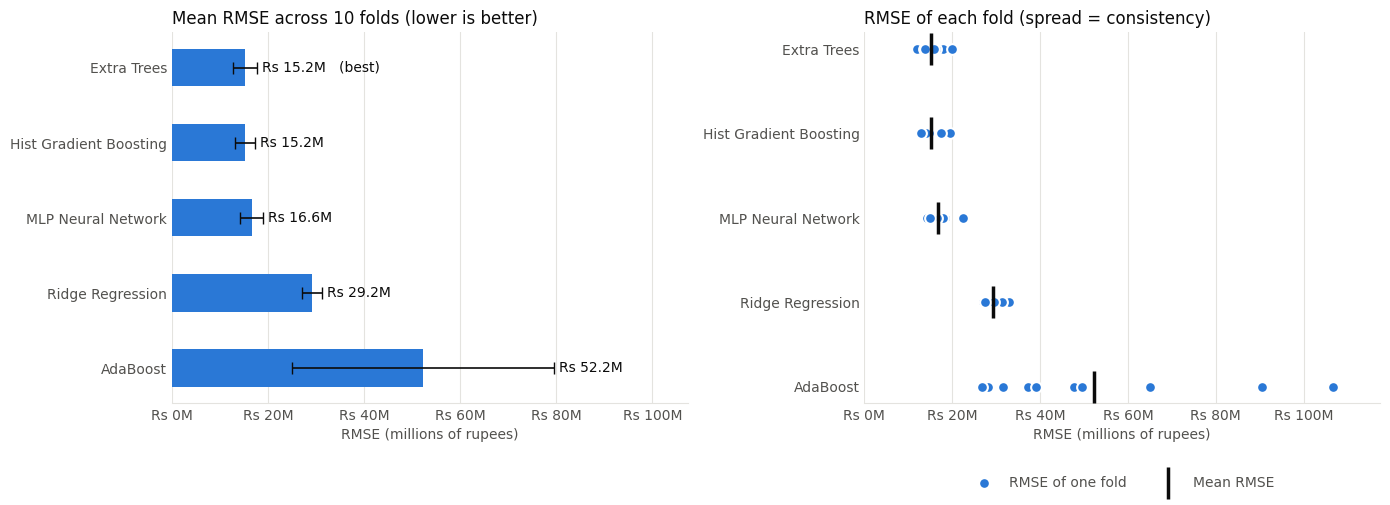

In [15]:
BAR_COLOR = "#2a78d6"
TEXT_COLOR = "#0b0b0b"
MUTED_TEXT = "#52514e"
GRID_COLOR = "#e4e3df"
millions = FuncFormatter(lambda value, _: f"Rs {value:,.0f}M")

def style_axis(ax):
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID_COLOR)
    ax.tick_params(colors=MUTED_TEXT, length=0)
    ax.xaxis.set_major_formatter(millions)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.grid(axis="x", color=GRID_COLOR, linewidth=0.8)
    ax.set_axisbelow(True)

order = summary.index.tolist()            # best algorithm first
positions = np.arange(len(order))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

means = summary["Mean RMSE (Rs M)"]
stds = summary["Std RMSE (Rs M)"]
ax1.barh(positions, means, height=0.5, color=BAR_COLOR,
         xerr=stds, error_kw=dict(ecolor=TEXT_COLOR, elinewidth=1.2, capsize=4))
for i, name in enumerate(order):
    label = f"Rs {means[name]:,.1f}M" + ("   (best)" if i == 0 else "")
    ax1.text(means[name] + stds[name] + means.max() * 0.02, i, label,
             va="center", color=TEXT_COLOR, fontsize=10)
ax1.set_yticks(positions, order, color=TEXT_COLOR)
ax1.invert_yaxis()
ax1.set_xlim(0, (means + stds).max() * 1.35)
style_axis(ax1)
ax1.set_title("Mean RMSE across 10 folds (lower is better)", loc="left", color=TEXT_COLOR, fontsize=12)
ax1.set_xlabel("RMSE (millions of rupees)", color=MUTED_TEXT)

for i, name in enumerate(order):
    ax2.scatter(per_fold_table[name], np.full(K, i), s=60, color=BAR_COLOR,
                edgecolor="white", linewidth=1.5, zorder=3,
                label="RMSE of one fold" if i == 0 else None)
    ax2.scatter(means[name], i, marker="|", s=500, color=TEXT_COLOR, linewidth=2.5, zorder=4,
                label="Mean RMSE" if i == 0 else None)
ax2.set_yticks(positions, order, color=TEXT_COLOR)
ax2.invert_yaxis()
ax2.set_xlim(0, per_fold_table.values.max() * 1.1)
style_axis(ax2)
ax2.set_title("RMSE of each fold (spread = consistency)", loc="left", color=TEXT_COLOR, fontsize=12)
ax2.set_xlabel("RMSE (millions of rupees)", color=MUTED_TEXT)
ax2.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, labelcolor=MUTED_TEXT)

plt.tight_layout()
plt.show()

## Step 9.4: Observations

> The numbers below come from our run on 128,828 properties. A different library version may change them slightly, but the pattern should be the same.

1. **Extra Trees has the lowest mean RMSE (Rs 15.21 M), but Hist Gradient Boosting is practically identical (Rs 15.22 M).** The gap is only about Rs 6,230, while the standard deviation across folds is about Rs 2.4 M for both. The two are **tied** (the winner of a fold alternates: Extra Trees won 5 folds, Hist Gradient Boosting won 5 folds).
2. **Accuracy vs. speed:** Hist Gradient Boosting took **63 s** for all 10 folds while Extra Trees took **444 s** (about **7× slower**). Because the RMSE is tied, we select the faster, smaller model for deployment (Step 10.1). The saved Extra Trees model would also be a very large file (~175 MB), too big for a normal GitHub upload.
3. **The MLP Neural Network is a clear third** (Rs 16.65 M, about 9% worse than the best). It learns non-linear patterns but needs more tuning (and more data per location) to match the tree-based models.
4. **Ridge Regression is far behind** (Rs 29.17 M, about 1.9× the best error). Property prices depend on **combinations** of location, size and type (a 1-Kanal house in DHA is worth many times a 1-Kanal house elsewhere), and a straight-line formula cannot capture that. This is the same lesson as Linear Regression in the Car Price notebook.
5. **AdaBoost is the worst and the least stable** (Rs 52.25 M, standard deviation Rs 27.22 M; its fold RMSE ranges from Rs 26.68 M to Rs 106.69 M). AdaBoost keeps increasing the weight of the examples it gets wrong, so a few extreme listings (multi-hundred-million properties) pull the whole model towards them.
6. **Every algorithm has its worst fold on Fold 4.** That test fold evidently contains the hardest, most expensive listings, which shows how strongly RMSE reacts to a few extreme prices (Step 3.1).
7. **The RMSE looks large compared with the average price** (even the best model is about 89% of the average price of Rs 17.1 M). This is mainly because prices are extremely skewed and RMSE squares the errors, so a handful of luxury listings dominate it. Ordinary listings are likely predicted much better than this single number suggests (see Step 12 for ways to measure that).
8. **Why 10 folds matter:** the best-vs-second-best ranking changes from fold to fold, and the worst fold is 1.7× worse than the best fold for the same model. A single train/test split could easily have crowned the wrong algorithm.

# Step 10: Train the Final Model
## Step 10.1: Select the Best Algorithm

**Cross validation is used to *choose* an algorithm, not to produce the final model.** The 10 models built during cross validation are thrown away.

**Selection rule:** we find the algorithm with the lowest mean RMSE, but when several algorithms are **within 1% of the best RMSE** the difference is smaller than the noise between folds, so we treat them as tied and pick the **fastest** one. A faster, smaller model is also easier to deploy: a 50-tree Extra Trees model is a very large file, which matters when uploading it to GitHub / the cloud.

In [16]:
lowest_rmse_name = summary.index[0]
lowest_rmse = summary.loc[lowest_rmse_name, "Mean RMSE (Rs M)"]

# algorithms within 1% of the best RMSE are treated as tied -> choose the fastest of them
tied = summary[summary["Mean RMSE (Rs M)"] <= lowest_rmse * 1.01]
print("Algorithms within 1% of the lowest RMSE:")
print(tied[["Mean RMSE (Rs M)", "Time (s)"]].round(2).to_string(), "\n")

best_algorithm_name = tied["Time (s)"].idxmin()
best_mean_rmse = summary.loc[best_algorithm_name, "Mean RMSE (Rs M)"]
best_std_rmse = summary.loc[best_algorithm_name, "Std RMSE (Rs M)"]

print(f"Lowest RMSE    : {lowest_rmse_name}")
print(f"Selected model : {best_algorithm_name}")
print(f"Expected RMSE  : Rs {best_mean_rmse:,.2f} M (+/- Rs {best_std_rmse:,.2f} M)")

Algorithms within 1% of the lowest RMSE:
                        Mean RMSE (Rs M)  Time (s)
Algorithm                                         
Extra Trees                        15.21    444.00
Hist Gradient Boosting             15.22     63.40 

Lowest RMSE    : Extra Trees
Selected model : Hist Gradient Boosting
Expected RMSE  : Rs 15.22 M (+/- Rs 2.13 M)


## Step 10.2: Train the Best Algorithm on All the Data

Now that we know the best algorithm, we train it on **all properties**. The cross-validation RMSE from Step 9 is our estimate of how well it will do on new, unseen properties.

In [17]:
final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", algorithms[best_algorithm_name]),
])

final_model.fit(X, y)
print(f"Final {best_algorithm_name} model trained on {len(X):,} properties.")

Final Hist Gradient Boosting model trained on 128,828 properties.


## Step 10.3: Save the Trained Model

The saved file contains the **whole pipeline** (imputer, scaler, one-hot encoder **and** the algorithm), so it can predict directly from raw property details. **This `.pkl` file is what you upload to Google Classroom and to the web app.**

In [18]:
MODEL_FILE = "property_price_model_full_dataset.pkl"
DOWNLOAD_MODEL = False          # set to True and re-run this cell to download the file in Colab

with open(MODEL_FILE, "wb") as f:
    pickle.dump(final_model, f)

print(f"Trained model saved as '{MODEL_FILE}' ({os.path.getsize(MODEL_FILE)/1e6:.1f} MB)")

if IN_COLAB and DOWNLOAD_MODEL:
    files.download(MODEL_FILE)

Trained model saved as 'property_price_model_full_dataset.pkl' (0.4 MB)


# Step 11: Execute the Application Phase
## Step 11.1: Take Input from User

By default the notebook uses the example property below so that **Run all** works without stopping. To type your own, set `USE_INTERACTIVE_INPUT = True` and run the cell again.

In [19]:
USE_INTERACTIVE_INPUT = False

example_property = {
    "latitude": 31.4697,
    "longitude": 74.2728,
    "baths": 4,
    "bedrooms": 4,
    "area_sqft": 2723,          # about 10 Marla
    "property_type": "House",
    "city": "Lahore",
    "purpose": "For Sale",
    "location": "DHA Defence",
}

def get_property_input():
    print("Enter property details:")
    prop = {
        "latitude": float(input("Latitude (e.g. 31.47): ")),
        "longitude": float(input("Longitude (e.g. 74.27): ")),
        "baths": int(input("Bathrooms: ")),
        "bedrooms": int(input("Bedrooms: ")),
        "area_sqft": float(input("Area in square feet: ")),
    }
    print("\nProperty types:", sorted(X["property_type"].unique()))
    prop["property_type"] = input("Property type: ").strip()
    print("Cities:", sorted(X["city"].unique()))
    prop["city"] = input("City: ").strip()
    prop["purpose"] = input("Purpose (For Sale / For Rent): ").strip()
    print("Most common locations:", X["location"].value_counts().index[:10].tolist())
    prop["location"] = input("Location: ").strip()
    return prop

user_input = get_property_input() if USE_INTERACTIVE_INPUT else example_property

print("Property details:")
for feature, value in user_input.items():
    print(f"  {feature:<14}: {value}")

Property details:
  latitude      : 31.4697
  longitude     : 74.2728
  baths         : 4
  bedrooms      : 4
  area_sqft     : 2723
  property_type : House
  city          : Lahore
  purpose       : For Sale
  location      : DHA Defence


## Step 11.2: Convert User Input into Feature Vector

The feature vector must have **exactly the same columns, in the same order,** as the training data. The saved pipeline scales and one-hot encodes it automatically.

In [20]:
feature_vector = pd.DataFrame([user_input])[numeric_features + categorical_features]
feature_vector

,latitude,longitude,baths,bedrooms,area_sqft,property_type,city,purpose,location
0,31.47,74.27,4,4,2723,House,Lahore,For Sale,DHA Defence


## Step 11.3: Load the Saved Model

In [21]:
with open(MODEL_FILE, "rb") as f:
    loaded_model = pickle.load(f)

print(f"Model loaded from '{MODEL_FILE}': {loaded_model.named_steps['regressor'].__class__.__name__}")

Model loaded from 'property_price_model_full_dataset.pkl': HistGradientBoostingRegressor


## Step 11.4: Model Prediction

In [22]:
predicted_price = loaded_model.predict(feature_vector)[0]

print(f"Predicted Price: Rs {predicted_price:,.0f}  (about Rs {predicted_price/1e6:,.2f} million)")
print(f"Typical error (cross-validation RMSE of {best_algorithm_name}): about Rs {best_mean_rmse:,.1f} million")

Predicted Price: Rs 27,260,183  (about Rs 27.26 million)
Typical error (cross-validation RMSE of Hist Gradient Boosting): about Rs 15.2 million


# Step 12: Execute the Feedback Phase

After deployment, feedback from users and real-estate experts is used to improve the model. Potential improvements:

1. **Train separate models for *For Sale* and *For Rent*.** They are on completely different price scales (millions vs. tens of thousands).
2. **Predict the logarithm of the price** (and convert back), or report MAE / percentage error next to RMSE, so that a few mansions do not dominate the error.
3. **Use more features**: street / block, age of the property, furnished or not, and keywords from the listing title. Also use the exact `location` instead of grouping rare locations.
4. **Tune hyper-parameters** with `GridSearchCV` (number of trees, learning rate, network size).
5. **Collect fresher data**: the listings are from 2018–2019 and prices have changed a lot since then, so the model should be retrained on current listings.

# Conclusion

In this notebook we compared **5 regression algorithms that were not used in the Car Price notebooks** (Ridge Regression, Extra Trees, Histogram Gradient Boosting, AdaBoost and an MLP Neural Network) on the **full Zameen.com property dataset (128,828 unique, cleaned listings)** using **10-fold cross validation** and **RMSE**.

- **Extra Trees** achieved the lowest mean RMSE (Rs 15.21 M) and **Hist Gradient Boosting** was practically tied (Rs 15.22 M). Since Hist Gradient Boosting is about 7× faster and produces a much smaller file, **Hist Gradient Boosting** was selected, trained on all 128,828 properties, saved as `property_price_model_full_dataset.pkl` (0.4 MB) and used to predict the price of a new property (example: Rs 27,260,183 for a 10-Marla house in DHA Lahore).
- **Ridge Regression and AdaBoost performed worst**, because property prices are strongly non-linear in the features and are dominated by a few extremely expensive listings.
- The RMSE is strongly affected by those listings, so it should be read together with the information in Step 3.1 and 9.4.
- Tree-based methods (Extra Trees, Hist Gradient Boosting) were clearly best for this tabular problem, which agrees with the Car Price results where tree-based models also won.

The trained model is deployed as a web app (see the link at the top of this notebook).